Device: cuda


README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

... (18 outputs left out)

epoch 1/1 | mean loss=0.5930
Accuracy=0.7960 | Precision=0.7342 | Recall=0.9280 | F1=0.8198
Confusion matrix [true 0/1 x pred 0/1]: [[166, 84], [18, 232]]
Training + evaluation time: 25.2s

=== max_length=256 ===


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


epoch 1/1 | mean loss=0.5233
Accuracy=0.8620 | Precision=0.8131 | Recall=0.9400 | F1=0.8720
Confusion matrix [true 0/1 x pred 0/1]: [[196, 54], [15, 235]]
Training + evaluation time: 50.7s

=== Controlled comparison ===
 max_length accuracy precision recall     f1 seconds
         64   0.7560    0.7336 0.8040 0.7672    32.4
        128   0.7960    0.7342 0.9280 0.8198    25.2
        256   0.8620    0.8131 0.9400 0.8720    50.7


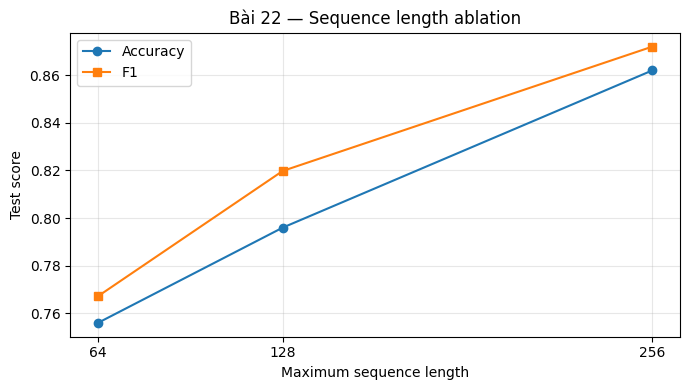


Trả lời câu hỏi phân tích: tăng sequence length không nhất thiết luôn làm model tốt hơn. Trong các cấu hình đã thử, max_length=256 có F1 cao nhất (0.8720) và Accuracy=0.8620. Hãy đối chiếu thêm thời gian chạy và các confusion matrix ở trên; kết luận chỉ áp dụng cho split, seed và một epoch của thí nghiệm này.


In [ ]:
# Bài 22 — Ablation / Analysis
# Thí nghiệm C: ảnh hưởng của max sequence length.
# Chỉ thay đổi max_length; giữ nguyên dữ liệu, split, model, seed, batch size,
# learning rate và số epoch để so sánh có kiểm soát.

!pip -q install datasets transformers scikit-learn

import random, time
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader, TensorDataset
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
import matplotlib.pyplot as plt

SEED = 42
TRAIN_PER_CLASS = 500
TEST_PER_CLASS = 250
MAX_LENGTHS = [64, 128, 256]
BATCH_SIZE = 16
LEARNING_RATE = 2e-5
EPOCHS = 1
MODEL_NAME = 'bert-base-uncased'
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


# Chọn cố định cùng 500 review mỗi nhãn train và 250 mỗi nhãn test.
set_seed(SEED)
raw_train = load_dataset('stanfordnlp/imdb', split='train')
raw_test = load_dataset('stanfordnlp/imdb', split='test')

def balanced_indices(dataset, per_class, seed):
    rng = random.Random(seed)
    labels = dataset['label']
    chosen = []
    for label in (0, 1):
        indices = [i for i, y in enumerate(labels) if y == label]
        chosen.extend(rng.sample(indices, per_class))
    rng.shuffle(chosen)
    return chosen

train_indices = balanced_indices(raw_train, TRAIN_PER_CLASS, SEED)
test_indices = balanced_indices(raw_test, TEST_PER_CLASS, SEED + 1)
train_texts = [raw_train[int(i)]['text'].replace('<br /><br />', ' ') for i in train_indices]
train_labels = np.array([raw_train[int(i)]['label'] for i in train_indices])
test_texts = [raw_test[int(i)]['text'].replace('<br /><br />', ' ') for i in test_indices]
test_labels = np.array([raw_test[int(i)]['label'] for i in test_indices])
print(f'Train: {len(train_texts)} balanced reviews | Test: {len(test_texts)} balanced reviews')


tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
results = []

for max_length in MAX_LENGTHS:
    print(f'\n=== max_length={max_length} ===')
    set_seed(SEED)  # cùng seed khởi tạo và thứ tự batch ở mỗi cấu hình
    start = time.time()

    train_enc = tokenizer(train_texts, truncation=True, padding='max_length', max_length=max_length, return_tensors='pt')
    test_enc = tokenizer(test_texts, truncation=True, padding='max_length', max_length=max_length, return_tensors='pt')
    train_ds = TensorDataset(train_enc['input_ids'], train_enc['attention_mask'], torch.tensor(train_labels, dtype=torch.long))
    test_ds = TensorDataset(test_enc['input_ids'], test_enc['attention_mask'], torch.tensor(test_labels, dtype=torch.long))
    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
    test_loader = DataLoader(test_ds, batch_size=32, shuffle=False)

    model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)
    model.train()
    for epoch in range(EPOCHS):
        total_loss = 0.0
        for step, batch in enumerate(train_loader, start=1):
            input_ids, attention_mask, labels = [x.to(DEVICE) for x in batch]
            optimizer.zero_grad()
            output = model(input_ids=input_ids, attention_mask=attention_mask, labels=labels)
            output.loss.backward()
            optimizer.step()
            total_loss += output.loss.item()
        print(f'epoch {epoch + 1}/{EPOCHS} | mean loss={total_loss / len(train_loader):.4f}')

    model.eval()
    all_preds = []
    with torch.no_grad():
        for input_ids, attention_mask, _ in test_loader:
            logits = model(input_ids=input_ids.to(DEVICE), attention_mask=attention_mask.to(DEVICE)).logits
            all_preds.extend(logits.argmax(dim=1).cpu().numpy())
    precision, recall, f1, _ = precision_recall_fscore_support(test_labels, all_preds, average='binary', zero_division=0)
    accuracy = accuracy_score(test_labels, all_preds)
    elapsed = time.time() - start
    matrix = confusion_matrix(test_labels, all_preds, labels=[0, 1]).tolist()
    results.append({'max_length': max_length, 'accuracy': accuracy, 'precision': precision,
                    'recall': recall, 'f1': f1, 'seconds': elapsed, 'confusion_matrix': matrix})
    print(f'Accuracy={accuracy:.4f} | Precision={precision:.4f} | Recall={recall:.4f} | F1={f1:.4f}')
    print(f'Confusion matrix [true 0/1 x pred 0/1]: {matrix}')
    print(f'Training + evaluation time: {elapsed:.1f}s')
    del model, optimizer, train_enc, test_enc, train_ds, test_ds, train_loader, test_loader
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


results_df = pd.DataFrame(results)
print('\n=== Controlled comparison ===')
print(results_df[['max_length', 'accuracy', 'precision', 'recall', 'f1', 'seconds']].to_string(index=False, formatters={
    'accuracy': '{:.4f}'.format, 'precision': '{:.4f}'.format, 'recall': '{:.4f}'.format,
    'f1': '{:.4f}'.format, 'seconds': '{:.1f}'.format
}))

plt.figure(figsize=(7, 4))
plt.plot(results_df['max_length'], results_df['accuracy'], marker='o', label='Accuracy')
plt.plot(results_df['max_length'], results_df['f1'], marker='s', label='F1')
plt.xlabel('Maximum sequence length')
plt.ylabel('Test score')
plt.title('Bài 22 — Sequence length ablation')
plt.xticks(MAX_LENGTHS)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

best = results_df.loc[results_df['f1'].idxmax()]
print(f'\nTrả lời câu hỏi phân tích: tăng sequence length không nhất thiết luôn làm model tốt hơn. '
      f'Trong các cấu hình đã thử, max_length={int(best.max_length)} có F1 cao nhất '
      f'({best.f1:.4f}) và Accuracy={best.accuracy:.4f}. Hãy đối chiếu thêm thời gian chạy '
      f'và các confusion matrix ở trên; kết luận chỉ áp dụng cho split, seed và một epoch của thí nghiệm này.')